# P4 이론: Transformer와 LLM

**주요 내용** 

원본 Transformer의 **Encoder–Decoder 아키텍처**를 이해한 후, 사전훈련된 모델을 이용한 **영어→스페인어 번역**과 **Decoder-only 언어 생성**을 연결한다. 마지막으로 두 구조를 결합하는 문서 검색·답변 생성 프로젝트의 기본 아이디어를 이해한다.

> 핵심 질문: **입력된 문장은 어떻게 숫자가 되고, Transformer는 이를 어떻게 처리하며, 모델은 어떻게 문장을 출력할까?**

**배경 자료:** Vaswani et al. (2017), *Attention Is All You Need*.


## 전체 학습 흐름

| 학습 주제 | 핵심 질문 | 실습 연결 |
|---|---|---|
| 텍스트 인코딩·Attention | 텍스트를 어떻게 숫자로 바꾸고, 토큰 사이의 관계를 어떻게 파악할까? | 토큰·ID·임베딩 모양 확인, 간단한 Attention |
| 원본 Transformer·번역 | 원본 Transformer의 Encoder와 Decoder는 어떻게 작동할까? | **영어→스페인어** 사전훈련 번역 모델 |
| Decoder-only·LLM | Encoder 없이 Decoder만 사용하면 어떻게 문장을 만들까? | 다음 토큰 확률, 텍스트 이어쓰기와 짧은 질의응답 |

각 주제의 원리를 살펴본 뒤 대응하는 실습으로 확인한다. **P4 프로젝트**에서는 아래에서 소개하는 Encoder-only의 문서 검색과 Decoder-only의 답변 생성을 연결한다. 프로젝트는 사전훈련 모델을 사용하며 모델을 직접 훈련하지 않는다.


## 먼저 살펴보는 원본 Transformer 구조

아래 그림은 **2017년에 발표된 원본 Transformer의 Encoder–Decoder 구조**이다. 왼쪽 **Encoder**는 입력 문장을 처리하고, 오른쪽 **Decoder**는 그 정보를 참고하여 출력 문장을 한 토큰씩 생성한다.

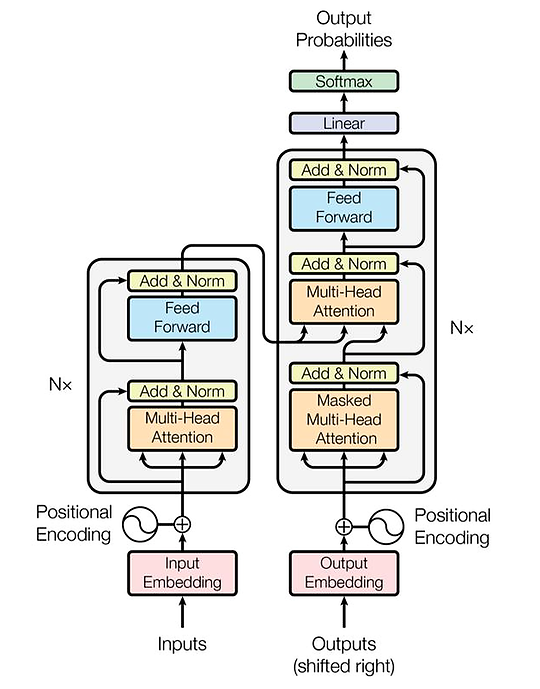

*출처: Vaswani et al. (2017), **Attention Is All You Need**, Figure 1.*

처음부터 모든 상자와 화살표를 이해할 필요는 없다. 먼저 다음의 전체 처리 흐름을 살펴보자.

**입력 임베딩**(Input Embedding) → **Encoder** → **Decoder** → **출력 확률**(Output Probabilities)

이후 토큰화, 임베딩, 위치 인코딩, Attention을 차례로 배우고, 뒤에서 이 그림을 다시 확인한다.


---
# 텍스트는 어떻게 Transformer의 입력이 되는가?

Transformer는 글자 자체를 계산하지 않는다. 문장을 **토큰**(Token)으로 나누고, 토큰에 정수 번호를 부여한 뒤, 각 번호에 대응하는 지정된 임베딩 차원의 실수 벡터를 사용한다. 이 벡터에 **위치 정보**를 반영하면 Transformer에 입력할 숫자 표현이 준비된다.

이 절에서는 하나의 문장을 끝까지 사용한다.

> **예제 문장:** `The unbelievable red car is fast.`

텍스트 벡터화를 설명하기 위해 아래 설정을 사용한다.

- 위 예문은 단어 기준 7개 토큰으로 구성된 텍스트를 사용한다.
- 각 토큰의 ID는 10~16이고,
- 총 토큰의 어휘집엔 10000 종류의 토큰이 포함된다고 가정한다.
- 임베딩으로 생성되는 벡터는 토큰 별로 각각 256차원을 갖는다.

Transformer에 입력되기 전까지의 과정은 다음과 같다. 

```text
          문장
           ↓
         표준화
           ↓
         토큰화
           ↓
 어휘집에서 토큰 ID 조회
           ↓
임베딩 테이블에서 벡터 조회
           ↓
      위치 정보 결합
           ↓
       Transformer
```


## 텍스트 표준화: 왜 필요할까?

**텍스트 표준화**(Text Standardization)는 입력 텍스트의 띄어쓰기, 대소문자, 문장부호 등 표기 방식이 다를 때, **미리 정한 규칙에 따라 표현을 일관되게 정리하는 과정**이다. 데이터의 특성과 모델에 따라 적용하는 규칙은 다르다.

공통 문장이 복사 과정에서 다음처럼 들어왔다고 하자.

```text
표준화 전: "  The   unbelievable  red car is fast.  "
표준화 후: "The unbelievable red car is fast."
```

이 예제에서는 (a) 앞뒤 공백을 제거하고 (b) 연속된 공백을 하나로 합친다. 코드로는 다음과 같다.

```python
import re
raw_text = "  The   unbelievable  red car is fast.  "
text = re.sub(r"\s+", " ", raw_text.strip())
print(text)
```

다른 표준화 규칙도 가능하다. 예를 들어 소문자화하면 `the unbelievable red car is fast.`로 바뀌고, 문장부호를 제거하면 마침표도 사라진다. 그러나 이런 변화는 뒤에서 만들 **토큰과 ID에 영향을 줄 수 있으므로**, 여기서는 대문자 `The`와 마침표 `.`를 그대로 유지한다.

**모든 모델에 공통인 표준화 규칙은 없다.** 이미 학습된 모델을 사용할 때는 임의로 표준화하기보다 **그 모델과 함께 제공되는 토크나이저**의 규칙을 따른다.


## 토큰화: 같은 문장을 여러 방식으로 나누기

**토큰화**(Tokenization)는 텍스트를 모델이 처리할 작은 단위인 **토큰**으로 나누는 과정이다. 토큰은 단어, 단어의 일부, 문장부호일 수 있다.

| 토큰화 방법 | 공통 문장을 나눈 결과 | 토큰 수 |
|---|---|---:|
| **단어 단위**(Word-level) | `The` / `unbelievable` / `red` / `car` / `is` / `fast` / `.` | 7 |
| **부분단어 단위**(Subword-level) | `The` / `un` / `believ` / `able` / `red` / `car` / `is` / `fast` / `.` | 9 |

**부분단어**(Subword)는 단어보다 작은 토큰 조각이다. 긴 단어나 드문 단어를 작은 조각으로 표현할 수 있다는 장점이 있다. 다만 위의 `un` / `believ` / `able`은 **개념 설명용 가상 분할**이며, 실제 모델이 이렇게 나누는지는 해당 토크나이저에 달려 있다. 부분단어는 언어학적 형태소와 반드시 일치하지 않는다.

이후의 수업용 ID와 임베딩 설명은 첫 번째 줄의 **7개 토큰**만 사용한다. 부분단어 방식은 동일한 예문에 대해 토큰화 결과가 어떻게 달라질 수 있는지 비교하기 위한 것이다.


## 어휘집은 무엇이며 어떻게 만들어질까?

**어휘집**(Vocabulary)은 **모델이 구분할 토큰 종류와 각 토큰에 대응하는 정수 ID를 모아 놓은 표**다. 텍스트가 입력될 때마다 새로운 어휘집을 만드는 것이 아니라, 보통 모델을 준비하는 과정에서 어휘집을 만들고 저장하여 일관되게 사용한다.

어휘집을 만드는 일반적인 흐름은 다음과 같다.

1. 모델 학습에 사용할 많은 텍스트를 모으고 표준화 규칙을 정한다.
2. 토큰 후보들을 수집한다. **단어 기준**이라면 각 단어의 등장 빈도를 셀 수 있다. **부분단어 기준**이라면 여러 문자·부분 문자열이 함께 등장하는 패턴을 학습하는 알고리즘을 사용할 수 있다.
3. 어휘집 크기와 특수 토큰을 정한다. 예컨대 어휘집 크기를 **10000개**로 정하면, 선택한 방식으로 토큰 종류 10000개를 구성한다.
4. 각 토큰에 고유한 ID를 부여하고, 어휘집과 토크나이저를 저장한다. 이후 새 문장에도 같은 규칙을 적용한다.

따라서 **어휘집 크기가 10000**이라는 말은 *한 문장의 토큰 수가 10000개*가 아니라, **구별 가능한 토큰의 종류가 10000개**라는 뜻이다. 실제 크기는 모델마다 다르다.

이번 예제에서는 전체 10000개 중 공통 문장에 필요한 일부 항목만 다음과 같이 가정한다.

| 토큰 | `[PAD]` | `[UNK]` | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **수업용 ID** | 0 | 1 | **10** | **11** | **12** | **13** | **14** | **15** | **16** |

`[PAD]`는 필요할 때 채움용으로 사용할 토큰이고, `[UNK]`는 단어 단위 어휘집에서 등록되지 않은 토큰을 표시하는 데 사용할 수 있다. 부분단어 토크나이저는 낯선 단어를 알려진 조각으로 분해하기도 한다.

```text
토큰   : [The, unbelievable, red, car, is, fast, .]
토큰 ID: [ 10,           11,  12,  13, 14,   15, 16]
```

ID는 토큰의 **식별 번호**일 뿐 의미를 나타내는 수치가 아니다. `red=12`, `car=13`이라고 해서 두 토큰의 의미가 비슷하다는 뜻은 아니다. 이 번호들은 설명을 위해 임의로 정한 것이며 실제 모델과 다를 수 있다.


## 임베딩 테이블에서 벡터를 조회하기

토큰 ID만으로는 토큰 사이의 언어적 관계를 표현하기 어렵다. Transformer는 토큰을 여러 개의 실수로 나타낸 **임베딩 벡터**(Embedding Vector)를 사용한다. 여기서는 **토큰 하나를 실수 256개로 표현**한다고 가정한다.

**임베딩 테이블**(Embedding Table)은 ID별 임베딩 벡터를 저장한 표다. 어휘집에 10000개 토큰이 있고 토큰 하나를 256개 숫자로 나타내면, 임베딩 테이블에는 10000개 행과 256개 열이 있다.

| 배열 | 행 수 | 열 수 | 모양 |
|---|---:|---:|---|
| 전체 임베딩 테이블 | 10000 | 256 | `(10000, 256)` |
| 이번 문장의 임베딩 | 7 | 256 | `(7, 256)` |

우리 문장의 ID 배열은 `[10, 11, 12, 13, 14, 15, 16]`이다. 따라서 전체 테이블을 복사하지 않고 **10, 11, 12, 13, 14, 15, 16번 행만 꺼낸다.**

```text
전체 임베딩 테이블 E : (10000, 256)

E[10] → The          의 256차원 벡터
E[11] → unbelievable 의 256차원 벡터
E[12] → red          의 256차원 벡터
E[13] → car          의 256차원 벡터
E[14] → is           의 256차원 벡터
E[15] → fast         의 256차원 벡터
E[16] → .            의 256차원 벡터

7개 벡터를 행으로 쌓은 결과 : (7, 256)
```

토큰 하나에 대응하는 벡터의 길이는 256으로 일정하지만, **문장의 토큰 수는 달라질 수 있다.** 아래 그림은 일곱 개의 벡터를 7행×256열로 배열한 모습을 나타낸다.


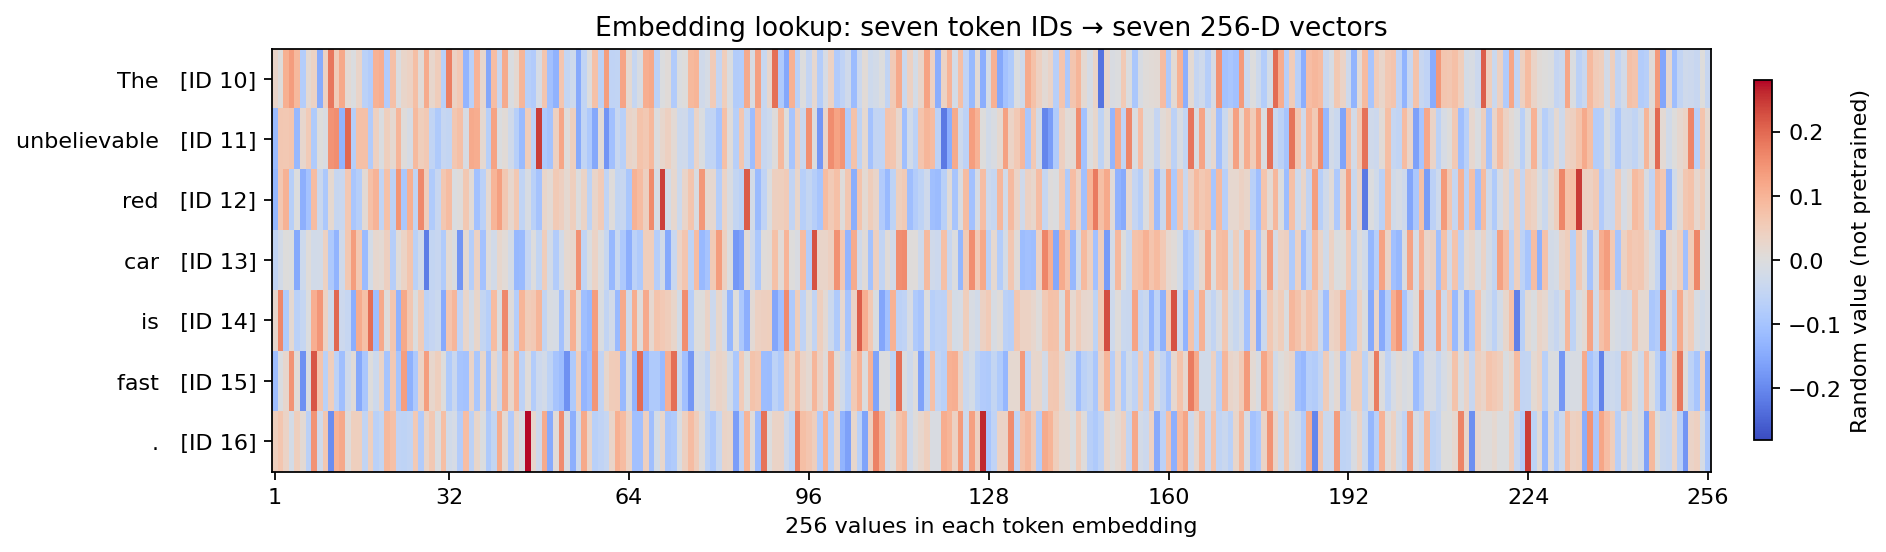

*한 행은 한 토큰의 벡터이고 열은 벡터의 성분이다. 그림의 숫자는 임베딩 테이블의 초기값을 예시한 것으로, 아직 언어를 학습한 결과가 아니다.*


## 임베딩 테이블의 숫자는 어떻게 학습될까?

앞에서는 어휘집의 토큰 ID를 사용해 임베딩 테이블의 특정 행을 조회하는 과정을 살펴보았다. 그렇다면 **각 행에 있는 256개 숫자는 어떻게 정해질까?**

임베딩 테이블은 모델이 사용하는 **가중치**(Weight)의 일부다. 가중치는 모델의 계산에 사용되는 숫자로, 학습 과정에서 값이 조정될 수 있다.

일반적으로 모델을 처음 만들 때는 임베딩 테이블에 작은 무작위 숫자를 넣어 **초기화**한다. 이 단계의 `car` 벡터가 이미 자동차의 의미를 알고 있는 것은 아니다. 그런 정보가 유용하게 표현되려면 학습 과정이 필요하다.

학습은 다음과 같은 흐름으로 진행된다.

1. 모델에 학습 데이터를 입력한다.
2. 모델이 주어진 **학습 과제**에 대해 결과를 예측한다.
3. 그 예측을 학습 데이터의 정답과 비교해 **오차**를 계산한다.
4. 오차가 작아지도록 임베딩을 포함한 여러 가중치를 조금씩 조정한다.
5. 많은 학습 사례에 대해 이 과정을 반복한다.

따라서 임베딩은 **사람이 토큰별로 의미를 정해 입력한 표가 아니라, 다른 가중치와 함께 학습되는 숫자들의 표**다. 학습된 벡터의 256개 좌표가 각각 색깔이나 속도처럼 하나의 정해진 뜻을 갖는 것도 아니다. 여러 값이 함께 작용하면서 언어 처리에 유용한 표현이 만들어진다.

앞의 임베딩 그림은 **초기화된 테이블의 모양을 보여주는 예시**다. 다음으로, 실제로 어떤 예측 과제를 통해 이 숫자들을 학습할 수 있는지 살펴보자.


## 언어 모델은 어떤 과제로 학습할까?

방금 살펴본 학습 과정에서 모델은 **무엇을 예측해야 할까?** 이는 모델의 용도에 따라 다르다. 여기서는 대표적인 예로 **언어 모델**(Language Model)을 살펴보자.

언어 모델은 텍스트에 나타나는 토큰들의 연결 패턴을 학습한다. 특히 **생성형 언어 모델**은 앞에 나온 토큰들을 바탕으로 **다음 토큰을 예측**하는 과제로 학습할 수 있다. 학습 문장 자체에서 다음 토큰을 정답으로 정할 수 있다.

공통 예문 `The unbelievable red car is fast.`를 사용하면 다음과 같은 학습 사례를 만들 수 있다.

| 모델에 입력하는 앞부분 | 실제 다음 토큰(정답) |
|---|---|
| `The` | `unbelievable` |
| `The unbelievable` | `red` |
| `The unbelievable red` | `car` |
| `The unbelievable red car` | `is` |
| `The unbelievable red car is` | `fast` |
| `The unbelievable red car is fast` | `.` |

가령 모델이 `The unbelievable red` 다음에 `car`가 나올 확률을 낮게 예측했다면, 정답과 예측 사이에 오차가 발생한다. 이 오차를 줄이기 위해 **임베딩 테이블과 Attention 등 모델의 가중치가 함께 조정**된다. 같은 과정을 수많은 문장에 반복하면 토큰의 임베딩도 점차 학습된다.

여기서 중요한 점은 **다음 토큰 예측이 임베딩만을 위한 별도 학습이 아니라, 언어 모델 전체를 학습하는 과제**라는 것이다. 임베딩 테이블은 그 과정에서 함께 바뀌는 여러 가중치 중 하나다.


## 이미 학습된 모델은 어떻게 사용하는가?

지금까지는 모델을 **처음 만들고, 학습을 통해 가중치를 조정하는 과정**을 설명했다. 하지만 실제 응용에서는 이 과정을 매번 처음부터 반복하지 않고, **이미 학습을 마친 모델의 가중치를 불러와 사용**하는 경우가 많다.

특히 대량의 텍스트로 언어의 일반적인 패턴을 먼저 학습하는 단계를 **사전훈련**(Pretraining)이라고 한다. 앞에서 본 다음 토큰 예측은 생성형 언어 모델의 대표적인 사전훈련 방법이다. 이렇게 학습된 모델은 이후 다른 작업에 활용하거나, 필요하면 특정 작업에 맞게 추가 학습할 수 있다.

**사전훈련된 모델**(Pretrained Model)을 불러온다는 것은 단순히 어휘집이나 임베딩을 새로 만드는 것이 아니라, **임베딩 테이블과 Attention 층 등 이미 학습된 가중치**를 가져오는 것이다. 따라서 같은 토큰 ID를 조회해도 임의로 초기화한 테이블에서 가져온 벡터와, 학습을 마친 테이블에서 가져온 벡터의 값은 다르다.

다만 모든 모델이 **다음 토큰 예측이라는 동일한 과제로 학습된 것은 아니다.** 예를 들어 영어→스페인어 번역 모델은 영어 입력과 스페인어 번역문의 짝을 이용해 학습할 수 있다. 모델의 종류에 따라 학습 과제가 다르지만, 학습된 가중치를 저장한 뒤 새 입력에 활용한다는 원리는 같다.

이번 **P4 실습**에서는 다음을 구분하여 확인한다.

- **임베딩 구조 관찰:** `(10000, 256)` 모양의 테이블을 임의의 숫자로 만든 뒤 ID에 맞는 행을 조회한다. 이 테이블은 학습된 가중치가 아니다.
- **사전훈련 모델 활용:** 이미 학습된 번역 모델을 불러와 임베딩 가중치를 살펴보고, 새로운 영어 문장을 스페인어로 번역한다. **가중치를 다시 학습하지 않는다.**

이후 Decoder-only 언어 생성과 프로젝트에서도 같은 방식으로 **학습을 마친 모델을 불러와 추론에 사용**한다.


## 새 문장이 들어오면 길이를 어떻게 처리할까?

**어휘집 크기**와 **임베딩 차원**은 모델에서 정해져 있지만, 실제로 입력받는 문장의 **토큰 수는 매번 달라질 수 있다.** 문장을 토큰화한 뒤 그 개수만큼 임베딩 행을 조회하면 된다.

| 입력 | 토큰 ID | 임베딩 모양 |
|---|---|---|
| 공통 문장 전체 | `[10, 11, 12, 13, 14, 15, 16]` | `(7, 256)` |
| 공통 문장의 앞부분 `The unbelievable red car` | `[10, 11, 12, 13]` | `(4, 256)` |

**최대 입력 길이**는 모델이 한 번에 처리할 수 있도록 지원하는 상한이다. 예를 들어 가상의 모델이 최대 512토큰을 처리할 수 있다고 해도 7개짜리 문장을 항상 512개 길이로 만들 필요는 없다.

### 여러 문장을 하나의 배치로 묶는 경우

서로 길이가 다른 입력을 **같은 크기의 배열**에 묶으려면 짧은 입력에 **패딩**(Padding)이라는 채움용 토큰을 붙이기도 한다. 아래는 7개짜리 문장과 앞부분 4개를 함께 처리하는 경우다.

```text
원래 A: [10, 11, 12, 13, 14, 15, 16]
원래 B: [10, 11, 12, 13]

배치의 가장 긴 입력에 맞춰 길이를 7로 정하면:
입력 A: [10, 11, 12, 13, 14, 15, 16]
입력 B: [10, 11, 12, 13,  0,  0,  0]
                             ↑ 0은 [PAD]에 해당
```

이 경우 **배치에 맞춘 길이 7**은 모델의 **최대 허용 길이와 별개**다. 다른 입력들을 묶으면 배치 길이가 달라질 수 있지만 모델이 지원하는 최대 길이가 변하는 것은 아니다. 한 문장만 입력하거나 가변 길이를 지원하는 계산 방법을 사용하면 패딩이 필요하지 않을 수도 있다.

패딩으로 추가한 위치는 원래 문장의 정보가 아니므로 **Attention 계산에서 실제 토큰처럼 참고하면 안 된다.** 이를 구별하는 표식을 **패딩 마스크**(Padding Mask)라고 한다. 이번 예시에서는 `1=실제 토큰`, `0=패딩`으로 약속한다.

```text
A의 패딩 마스크: [1, 1, 1, 1, 1, 1, 1]
B의 패딩 마스크: [1, 1, 1, 1, 0, 0, 0]
```

**패딩은 길이를 맞추고, 마스크는 채움용 위치를 구별한다.** 마스크 값의 약속은 라이브러리에 따라 달라질 수 있다. 뒤에서 배우는 **Causal Mask**는 미래의 출력 토큰을 보지 못하게 한다는 점에서 목적이 다르다.

따라서 이 배치의 ID 배열은 `(2, 7)`이고, 임베딩 배열은 `(2, 7, 256)`이다. 순서대로 입력 두 개, 배치에서 맞춘 길이 7, 토큰당 256개 실수를 뜻한다.


## 위치 인코딩: 단어의 순서를 어떻게 알려줄까?

임베딩 테이블에서 `car`의 벡터 `E[13]`을 가져왔다고 하자. 이것은 **어떤 토큰인가**를 나타내지만, 그 토큰이 **문장의 몇 번째 위치에 있는지**까지 알려주지는 않는다. 원본 Transformer는 이를 위해 **위치 인코딩**(Positional Encoding)을 사용했다.

| 위치 번호 $p$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| 토큰 | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
| ID | 10 | 11 | 12 | 13 | 14 | 15 | 16 |

### 위치 번호를 256개의 숫자로 바꾸기

원본 Transformer에서는 **사인·코사인 함수**를 이용해 위치 $p$마다 길이 256인 벡터 $P[p]$를 계산한다. 이 방식은 **위치 벡터의 숫자를 훈련으로 학습하지 않는다.** 위치 번호와 차원 번호만 알면 정해진 공식으로 계산한다.

첫 번째와 두 번째 성분은 다음과 같다.

$$
P[p,0]=\sin(p), \qquad P[p,1]=\cos(p)
$$

그렇다면 나머지 성분은 무엇일까? **같은 사인·코사인이지만 위치가 바뀔 때 숫자가 변하는 속도를 달리**한다. 예를 들어 차원이 256이라면 65번째와 66번째 성분(인덱스 64, 65)은 다음처럼 계산한다.

$$
P[p,64]=\sin(p/10), \qquad P[p,65]=\cos(p/10)
$$

129번째와 130번째 성분(인덱스 128, 129)은 각각 $\sin(p/100)$, $\cos(p/100)$으로 계산한다. 

실제로 2017년 Transformer 논문에서는 다음 공식을 사용했습니다.

$$P[p,2i]=\sin\left(\frac{p}{10000^{2i/d\_{\text{model}}}}\right)$$

$$P[p,2i+1]=\cos\left(\frac{p}{10000^{2i/d\_{\text{model}}}}\right)$$

**앞부분 성분은 빠르게 변하고, 다른 성분은 천천히 변한다.** 이 다양한 숫자 패턴을 조합하면 각 위치의 벡터를 구별할 수 있다.

| 위치 $p$ | $\sin(p)$ | $\cos(p)$ | $\sin(p/10)$ | $\cos(p/10)$ | $\sin(p/100)$ |
|---:|---:|---:|---:|---:|---:|
| 0 | 0.000 | 1.000 | 0.000 | 1.000 | 0.000 |
| 1 | 0.841 | 0.540 | 0.100 | 0.995 | 0.010 |
| 3 | 0.141 | -0.990 | 0.296 | 0.955 | 0.030 |
| 6 | -0.279 | 0.960 | 0.565 | 0.825 | 0.060 |

이 표는 전체 256개 숫자 가운데 다섯 개만 보여준다. 나머지 성분도 서로 다른 주기의 사인·코사인 값으로 채운다. 실습에서는 이 차이를 그래프로 확인한다.

### 임베딩과 위치 벡터를 결합하기

$d_{\mathrm{model}}$은 Transformer 내부에서 한 토큰을 표현하는 **벡터 차원**을 뜻한다. 이번 예제에서는 $d_{\mathrm{model}}=256$이다. 토큰 임베딩과 위치 벡터의 길이가 모두 256이므로 **같은 성분끼리 더할 수 있다.** 원본 Transformer는 임베딩에 $\sqrt{d_{\mathrm{model}}}$을 곱한 후 위치 벡터를 더한다.

$$
\mathbf{x}_p = \sqrt{d_{\mathrm{model}}}\,E[\mathrm{ID}_p]+P[p]
$$

예를 들어 위치 3의 `car`는 `E[13]`에 `P[3]`을 더한다. 벡터를 옆으로 이어 붙여 512차원으로 만드는 것이 아니라 **같은 자리의 숫자를 더하므로 256차원 그대로**다.

| 배열 | 모양 |
|---|---|
| 토큰 일곱 개의 임베딩 | `(7, 256)` |
| 위치 0~6의 벡터들 | `(7, 256)` |
| 두 벡터들을 성분별로 결합한 입력 | `(7, 256)` |

### 위치 벡터도 학습될까?

**원본 Transformer의 사인·코사인 위치 인코딩은 학습하지 않는다.** 같은 모델 설정에서는 어떤 문장이 들어와도 **위치 번호에 따라 위치 벡터가 정해진다.** 예를 들어 위치 0에는 `P[0]`, 위치 1에는 `P[1]`을 계산한다. 다만 실제 단어 앞에 특수 토큰이 추가되면 그 단어에 배정되는 위치 번호가 달라질 수 있다.

반면 **다른 모델들은 위치별 벡터를 가중치처럼 학습**하기도 한다. 현대 LLM에는 RoPE 같은 다른 위치 표현 방법도 쓰인다. 위치 정보를 표현하는 방법은 여러 가지지만, 여기서는 **원본 Transformer가 숫자 패턴으로 토큰의 순서를 전달한다는 원리**가 중요하다.


## 토큰 임베딩과 문맥 표현은 다르다

같은 모델의 가중치가 고정되어 있다면 `car`의 ID는 항상 `13`이고, 임베딩 테이블에서 같은 `E[13]`을 가져온다. 그러나 `car`가 문장에서 놓인 위치가 달라지면 **더해지는 위치 벡터**가 달라진다. 그리고 다음 절의 **Self-Attention**을 거치면서 주변 토큰의 정보가 반영된다.

따라서 다음 세 가지는 구분해야 한다.

- **토큰 ID:** 어휘집의 식별 번호
- **토큰 임베딩:** 임베딩 테이블에서 가져온 벡터
- **문맥을 반영한 표현:** 위치 정보와 Attention 등의 계산을 거친 벡터

앞에서는 텍스트를 계산 가능한 숫자로 바꾸었다. 이어지는 Attention에서는 이 숫자들이 **다른 토큰의 정보를 어떻게 반영하는지** 살펴본다.


## 텍스트 입력 과정 정리

```text
"  The   unbelievable  red car is fast.  "
                  ↓  표준화
The unbelievable red car is fast.
                  ↓  단어 단위 토큰화
[The, unbelievable, red, car, is, fast, .]     7개 토큰
                  ↓  어휘집에서 ID 조회
[10, 11, 12, 13, 14, 15, 16]                   모양 (7,)
                  ↓  임베딩 테이블 (10000, 256)에서 7개 행 조회
토큰 임베딩 벡터                                 모양 (7, 256)
                  ↓  위치 0~6에 해당하는 위치 벡터 결합
Transformer 입력                               모양 (7, 256)
```

**핵심:** 어휘집은 **토큰 종류의 목록**, ID는 **식별 번호**, 임베딩은 **학습 가능한 실수 벡터**다. 원본 Transformer의 사인·코사인 위치 벡터는 **학습하지 않고 계산**하며, 학습된 모델을 불러오면 이미 조정된 임베딩·Attention 가중치를 그대로 사용할 수 있다.

**확인 질문:** 어휘집은 어떻게 만들어지는가? `(10000, 256)`과 `(7, 256)`은 왜 다른가? 임베딩 표의 숫자는 언제 바뀌는가? 위치 `P[0]`의 숫자는 어떤 문장이 들어오든 같은가?


---
# 단어 사이의 관계를 어떻게 파악하는가? — Self-Attention과 Q·K·V

앞에서 `The unbelievable red car is fast.`를 **7개 토큰**, 각 **256차원 벡터**로 나타냈다. 이제 이 토큰들이 **서로 정보를 참고해 문맥에 맞는 표현으로 바뀌는 과정**을 살펴보자.

예를 들어 `car`라는 토큰의 표현을 만들 때 `red`(색깔)와 `fast`(자동차의 속도에 관한 서술) 같은 주변 토큰 정보가 도움이 될 수 있다. Self-Attention은 **어떤 토큰을 얼마만큼 참고할지 계산해 다른 토큰의 정보를 섞는 방법**이다.


## Q·K·V는 각 토큰의 역할이 아니라 '정보를 계산하는 세 벡터'다

| 구분 | 역할 | 직관적인 질문 |
|---|---|---|
| **Q**(Query) | 현재 토큰이 찾는 정보의 조건 | `car`를 표현하려면 어떤 정보를 참고하면 될까? |
| **K**(Key) | 각 토큰이 제공하는 정보의 비교용 표지 | `red`, `fast` 등이 `car`의 요구와 얼마나 관련될까? |
| **V**(Value) | 실제로 가중합하여 가져올 정보 | 참고할 토큰의 정보 중 얼마나 반영할까? |

Q·K·V는 '단어를 셋으로 나눈다'는 뜻이 아니다. **모든 토큰 표현에서 Q·K·V를 각각 계산**한다. 실제 Transformer는 학습된 세 종류의 변환 행렬을 사용한다.

1. 현재 토큰의 Q를 다른 토큰들의 K와 비교하여 **관련성 점수**를 얻는다.
2. 점수를 **Softmax**로 변환하여 합이 1인 **Attention 가중치**를 얻는다.
3. 각 토큰의 V에 가중치를 곱해 더한다. 이것이 **현재 토큰에 반영될 문맥 정보**가 된다.

아래의 숫자는 원리 확인용으로 **인위적으로 설계한 값**이다. 실제 사전훈련 모델의 Attention을 추출한 결과가 아니다.


## 같은 문장의 7개 토큰에 Attention을 적용하면

수업용 ID `[10, 11, 12, 13, 14, 15, 16]`에 대응하는 벡터를 `(7, 256)`으로 준비했다고 하자. 여기서는 `car`(네 번째 토큰)가 `red`와 `fast`에 더 큰 가중치를 주도록 예제 Q·K를 설정한다.

| `car`가 참고하는 토큰 | The | unbelievable | red | car | is | fast | . |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Attention 가중치**(교육용) | 0.047 | 0.047 | **0.344** | 0.126 | 0.047 | **0.344** | 0.047 |

표의 값은 반올림했으므로 합이 1과 약간 다르게 보일 수 있다. 원래 계산에서는 **정확히 1**이다.

`car`의 새 정보는 `red`와 `fast`의 **V 벡터**에 큰 비중을 주고, 나머지 토큰의 V도 해당 가중치만큼 섞어 얻는다. **어떤 토큰을 더 참고할지**가 중요하며 학생이 256개 숫자를 일일이 계산할 필요는 없다.


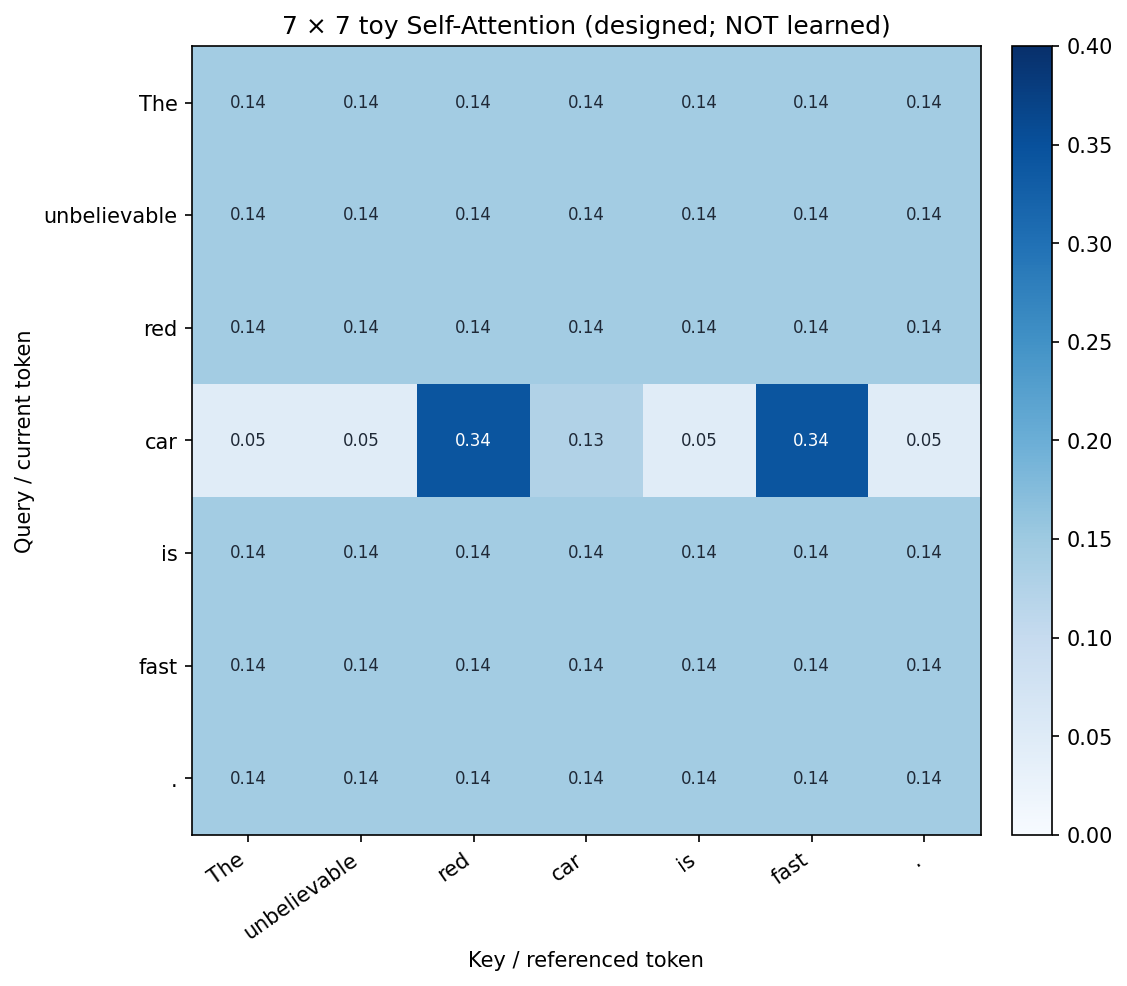

*그림: 행은 현재 토큰(Query), 열은 참고하는 토큰(Key)이다. `car` 행에서 `red`와 `fast`의 가중치가 높게 보이도록 **교육용 Q·K 값을 설정**했다. 다른 토큰 관계를 학습한 실제 모델 결과는 아니다.*


## 왜 Attention 표는 7×7인데 결과는 7×256일까?

| 단계 | 배열 모양 | 의미 |
|---|---|---|
| 입력 X | `(7, 256)` | 7개 토큰의 256차원 표현 |
| Q, K, V | 각각 `(7, 256)` | 하나의 Head를 단순화한 설정 |
| Q와 K의 관련성 점수 | `(7, 7)` | **7개 토큰 각각이 나머지 7개를 얼마나 참고할지** |
| Softmax 가중치 | `(7, 7)` | 행별 가중치 합이 1 |
| 가중치 × V | `(7, 256)` | 각 토큰에 문맥 정보가 반영된 256차원 표현 |

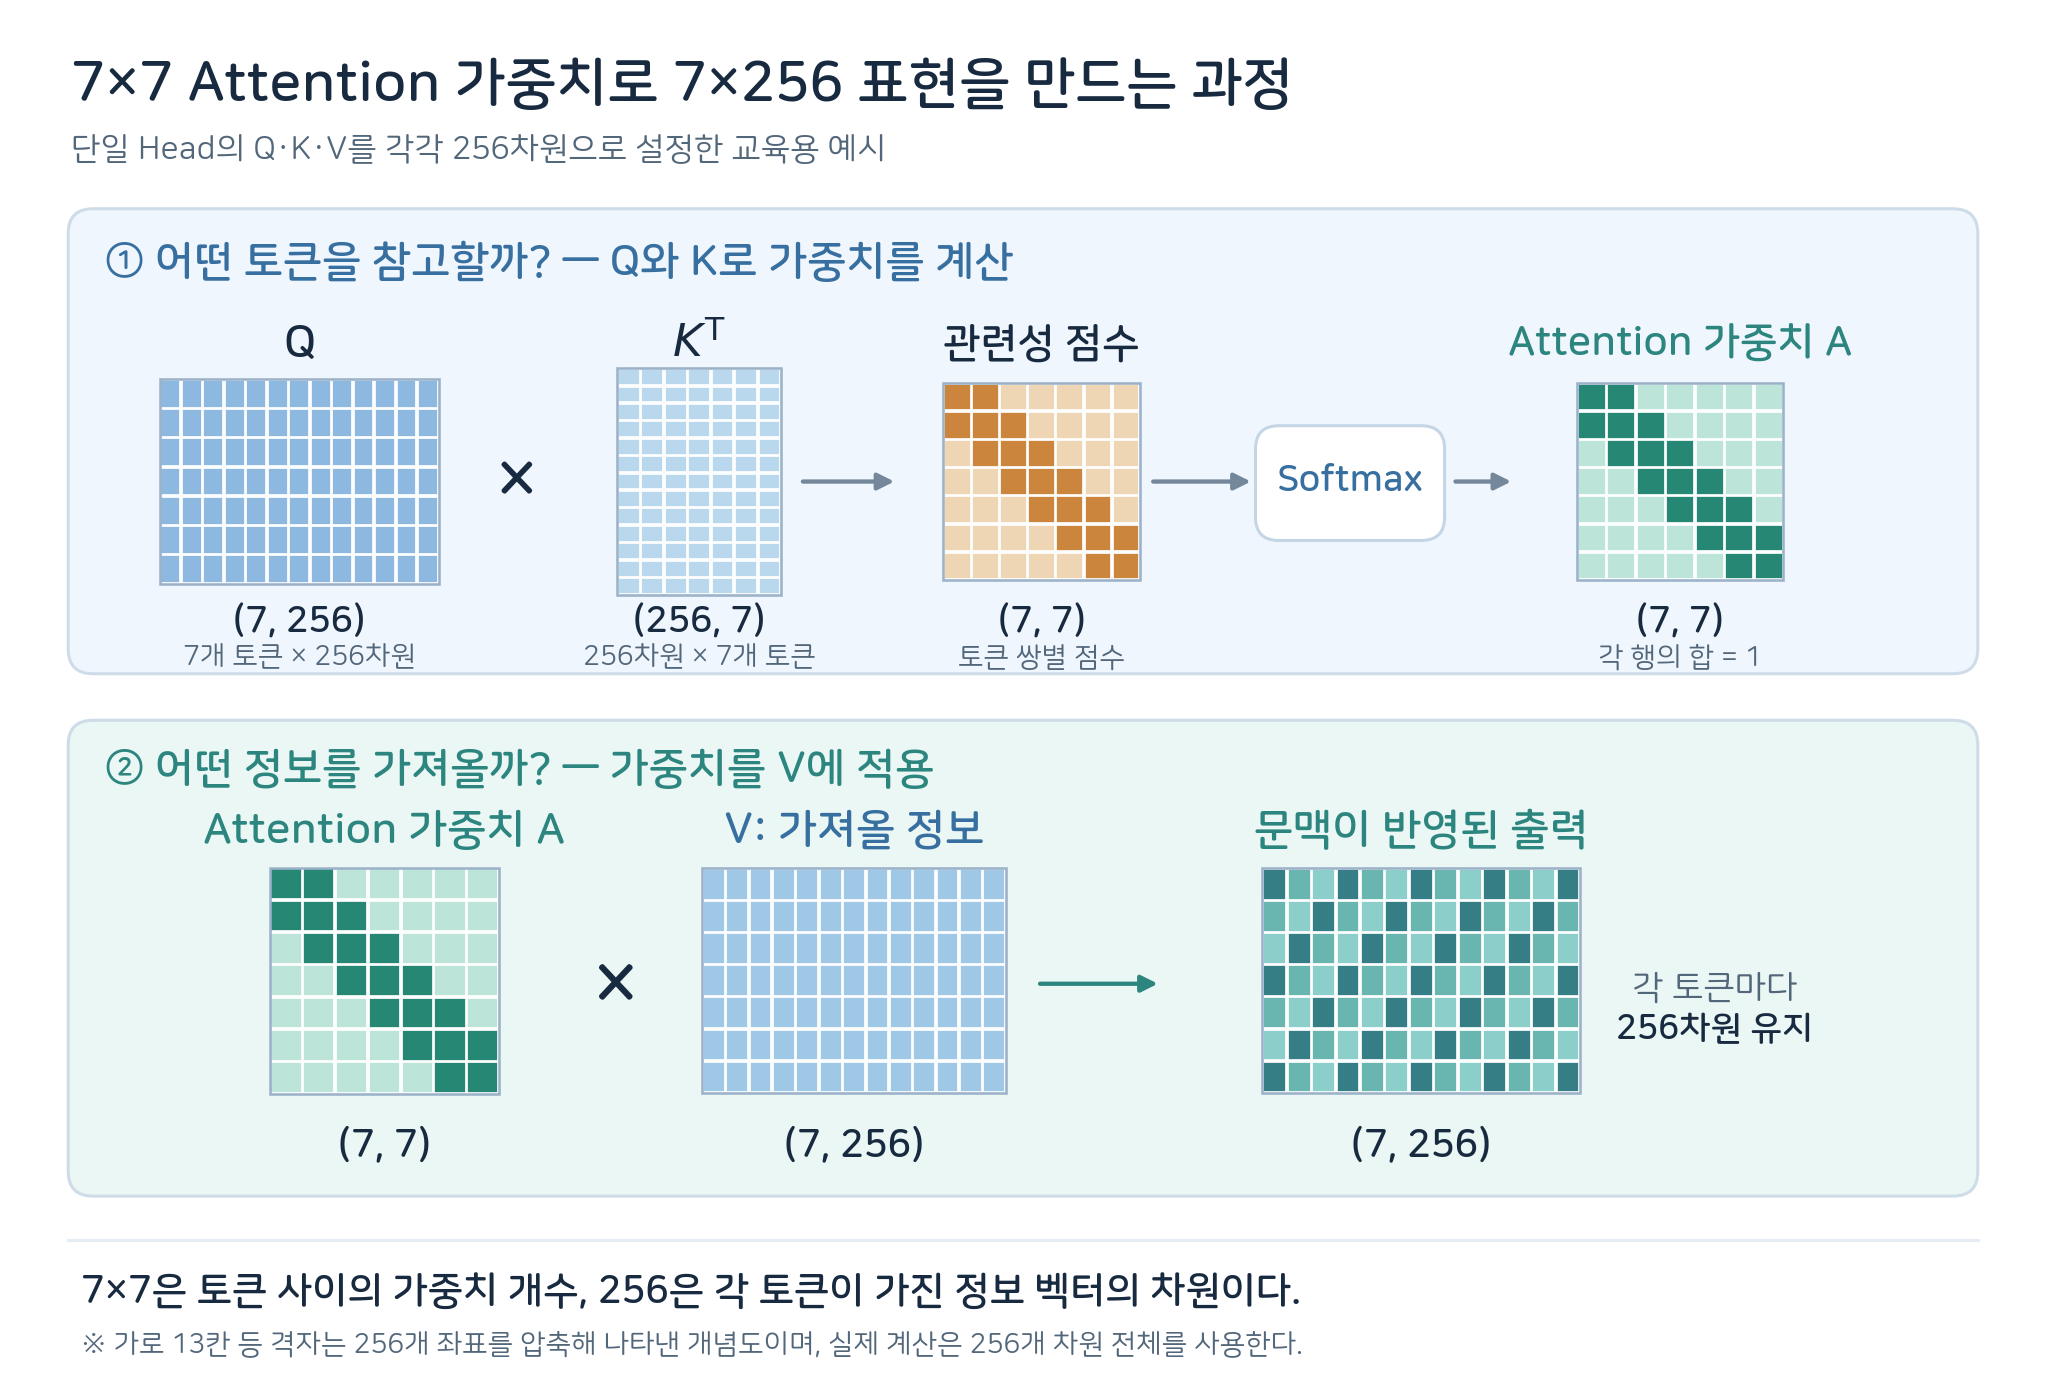

*그림: 위쪽에서는 Q와 K를 이용해 토큰 사이의 가중치를 계산하고, 아래쪽에서는 그 가중치를 V의 256차원 정보에 적용한다. 행렬 안의 칸은 차원을 줄여 표현한 개념도이다.*

Attention은 임베딩 차원을 7차원으로 줄이는 작업이 아니다. **7×7 가중치 표로 어떤 토큰의 정보를 얼마나 반영할지 결정**하고, 그 결과를 **256차원 벡터들에 적용**하는 과정이다.

원리를 한 줄로 쓰면 다음과 같다.

$$
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}\right)V
$$

이 수식의 의미는 **Q·K로 가중치를 정하고 V를 가중합한다**는 것이다. 자세한 행렬 계산은 이번 수업에서 요구하지 않는다.

**Attention 핵심 요약:** **Q·K는 어디를 참고할지 정하고, V는 실제로 가져올 정보**다. 7개 토큰의 Attention 가중치 표는 `(7, 7)`이지만, 출력된 표현은 `(7, 256)`이다.


## Multi-Head Attention은 왜 사용할까?

단일 Head가 관계를 한 가지 방식으로 계산한다면, 여러 Head는 **서로 다른 변환을 사용해 다양한 관계를 함께 계산**할 수 있다.

예를 들어 **토큰 표현 차원 256, Head 4개, Head당 차원 64**로 설계할 수 있다. 각 Head는 256차원 입력을 단순히 64개씩 잘라 쓰는 것이 아니라, **서로 다른 학습된 선형변환**으로 Q·K·V를 계산한다.

```text
입력 토큰 표현: 7 × 256
    ├─ Head 1 : 7 × 64 ─┐
    ├─ Head 2 : 7 × 64 ─┤
    ├─ Head 3 : 7 × 64 ─┼→ 이어 붙이기 → 7 × 256 → 출력 변환
    └─ Head 4 : 7 × 64 ─┘
```

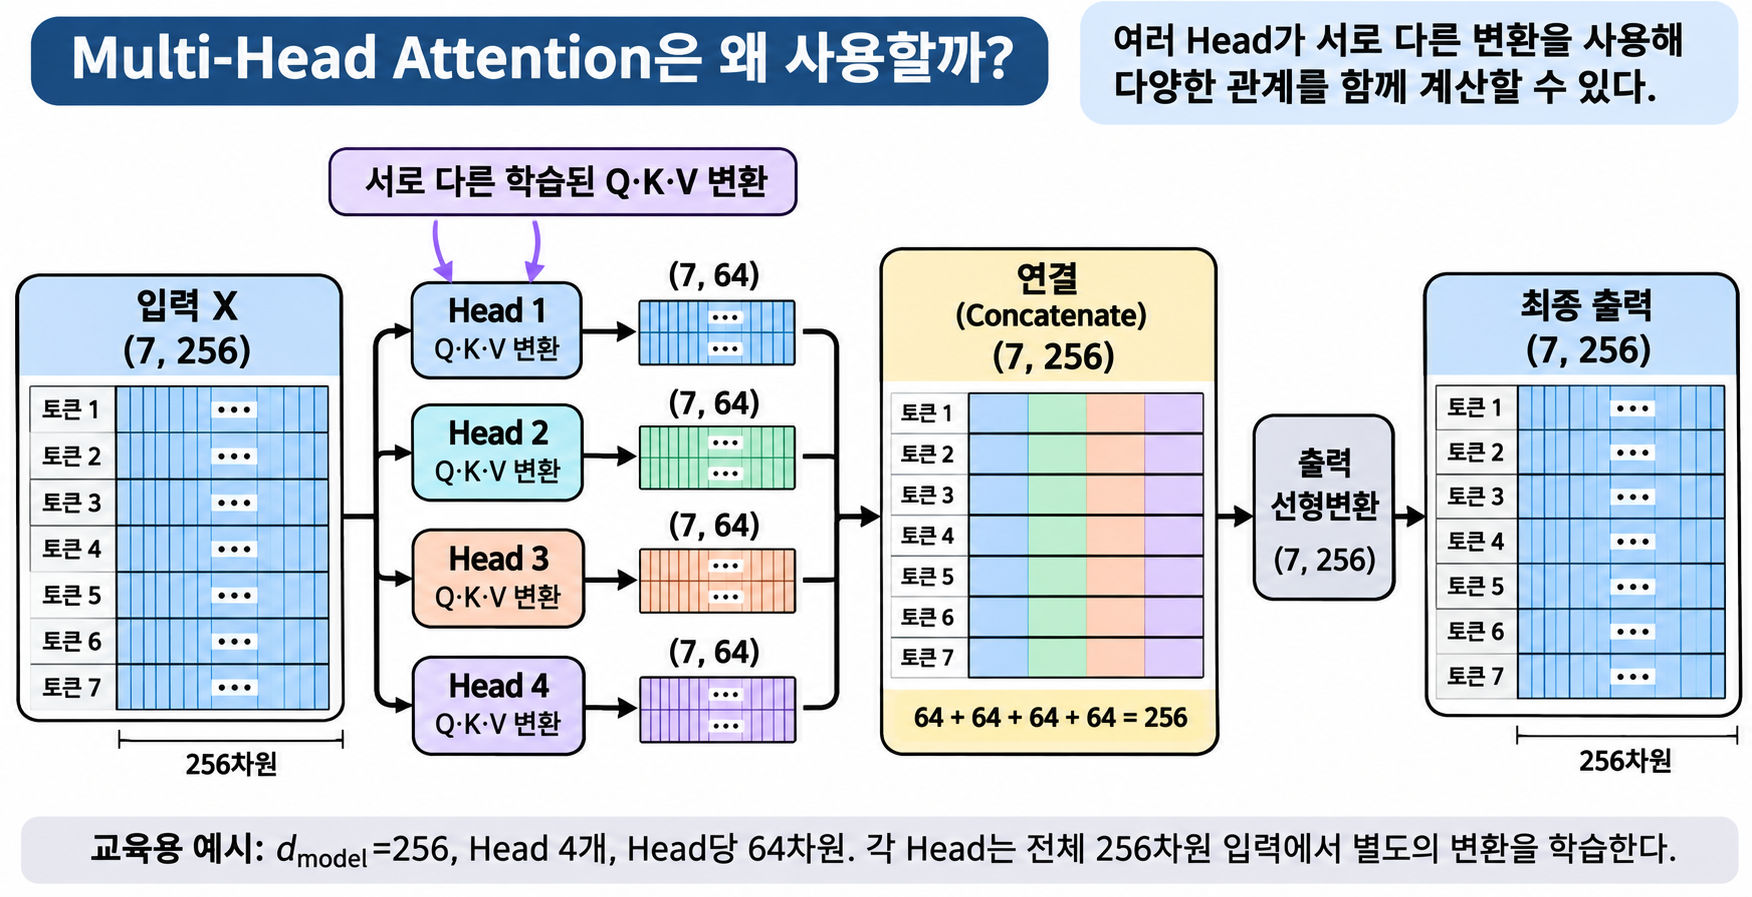

*그림: 각 Head는 **전체 `(7, 256)` 입력**에서 서로 다른 가중치를 사용해 Q·K·V를 계산한다. Head별 `(7, 64)` 출력을 연결하면 `(7, 256)`이 되고, 출력 선형변환 후에도 `(7, 256)`이 유지된다. 이는 **4개 Head를 동일한 차원으로 설정한 교육용 예시**다.*

### 원본 Transformer에서는 어떻게 설정했을까?

2017년 논문 *Attention Is All You Need*에 제시된 **원본 Transformer의 기본 모델**은 다음과 같이 설계되었다.

| 항목 | 원본 Transformer의 기본 모델 | 이 수업의 256차원 예제 |
|---|---:|---:|
| 토큰 표현 차원($d_{model}$) | **512** | **256** |
| Attention Head 수 | **8개** | **4개** |
| Head 하나의 Q·K·V 차원 | **64** | **64** |
| Head 출력 연결 후 차원 | **512** | **256** |

즉, 원래 모델에서는 **64차원 Head 8개**의 결과를 연결하여 512차원으로 만든다. 수업에서 256차원을 사용한 것은 구조를 쉽게 관찰하기 위한 **교육용 설정**이다.

### 모든 Head의 차원이 같아야 할까?

**반드시 그렇지는 않다.** 예를 들어 256차원 출력이 필요할 때 네 Head의 출력 차원을 **32, 64, 64, 96**으로 다르게 설계하여 연결할 수도 있다. 다만 **원본 Transformer와 대부분의 표준 구현은 모든 Head를 같은 차원으로 설계**한다. 계산을 효율적으로 병렬화하기 쉽기 때문이다.

Head별 차원을 다르게 하려면 일반적인 균일 크기 Head 구현 대신 별도의 변환과 결합 과정이 필요하다. 또한 **Head 출력 차원의 합이 반드시 모델 차원과 같아야 하는 것도 아니다.** 연결한 결과에 출력 선형변환을 적용하여 모델이 요구하는 차원으로 맞출 수 있다.

주의할 점은 **각 Head에서 Q와 K는 관련성 점수를 계산할 수 있도록 서로 같은 차원이어야 한다**는 것이다. Head의 차원이 다르다는 말은 *Head끼리* 차원이 다를 수 있다는 뜻이다.

마지막으로 어떤 Head가 무조건 색깔이나 문법만 담당한다고 단정할 수 없다. 원본 Transformer 블록에는 Attention 외에도 **Feed Forward 층, 잔차 연결, 정규화** 등이 포함된다.


## Encoder와 Decoder가 사용하는 Attention은 어떻게 다를까?

지금까지는 하나의 문장에 대해 Q·K·V를 계산하는 **Self-Attention의 공통 원리**를 배웠다. 그런데 원본 Transformer의 Encoder–Decoder 구조에서는 Attention이 **세 위치**에 등장한다. 계산의 기본 원리는 같지만, **Q·K·V를 어느 쪽에서 가져오는지**, 그리고 **어떤 토큰까지 참고할 수 있는지**가 다르다.

### 원본 Transformer 구조에서 세 위치 찾기

아래 그림은 처음 살펴본 **원본 Transformer의 아키텍처 그림**에서 세 Attention 블록에 번호를 붙인 것이다. 왼쪽 Encoder에는 ①이 하나, 오른쪽 Decoder에는 아래에서 위로 ②와 ③이 있다. **N×**는 해당 블록이 여러 층 반복된다는 의미이며, 이 세 종류의 Attention은 각 해당 층에서 작동한다.

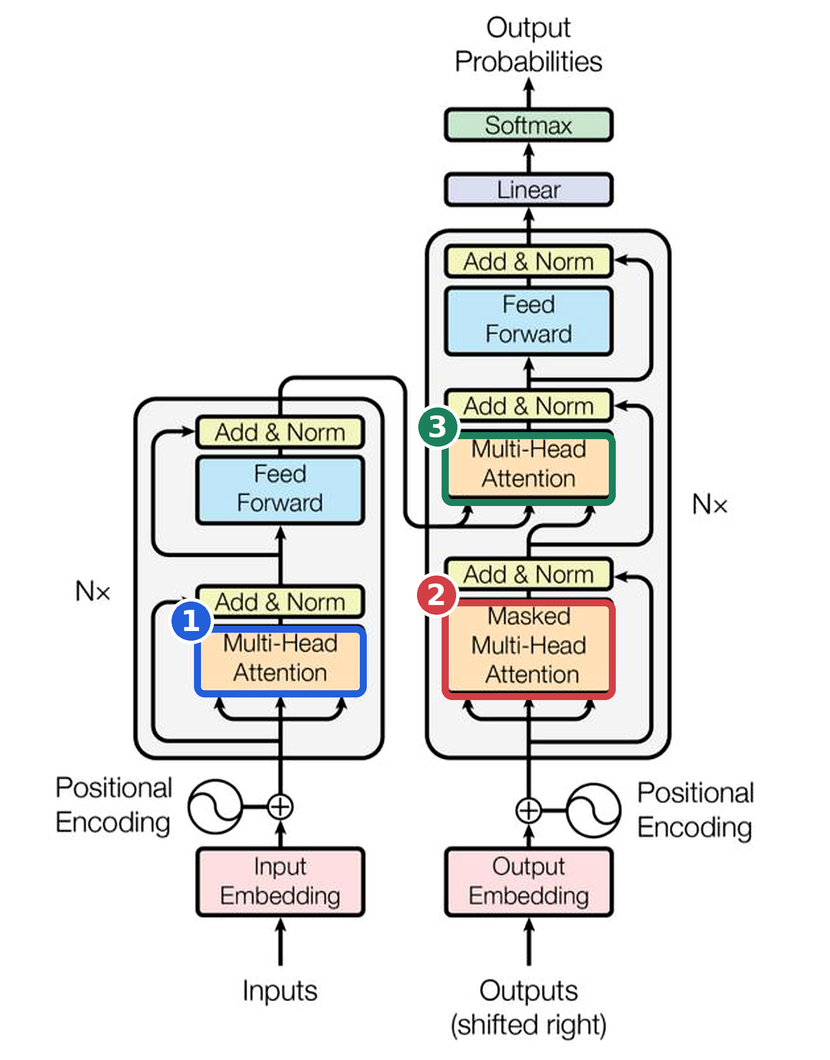

*그림: Vaswani et al. (2017), 「Attention Is All You Need」의 원본 구조도에서 ① Encoder Self-Attention, ② Decoder Masked Self-Attention, ③ Encoder–Decoder Cross-Attention의 위치를 표시했다.*

| 그림 번호 | Attention 종류 | Q의 출처 | K·V의 출처 | 참고할 수 있는 토큰 |
|---|---|---|---|---|
| **①** | **Encoder Self-Attention** | Encoder의 입력 표현 | 같은 Encoder 표현 | 입력 문장 전체의 토큰 |
| **②** | **Decoder Masked Self-Attention** | Decoder의 현재 층 표현 | 같은 Decoder 표현 | 현재 위치와 그 이전의 출력 쪽 토큰 |
| **③** | **Cross-Attention** | Decoder의 표현 | Encoder가 만든 출력 표현 | 영어 입력 문장의 토큰 전체 |

### ① Encoder Self-Attention: 입력 문장 전체를 참고한다

Encoder는 입력 문장의 각 토큰을 문맥에 맞게 표현해야 한다. 예를 들어 영어 입력 `The unbelievable red car is fast.`를 7개 토큰으로 나누면, `car`는 **앞의 `red`도, 뒤의 `fast`도** 참고할 수 있다. 따라서 여기서는 미래 위치를 가리는 Causal Mask를 사용하지 않는다.

- **Q·K·V의 출처:** 모두 Encoder 내부의 **같은 입력 토큰 표현들**이다. 각각 다른 가중치로 변환하므로 Q, K, V가 숫자까지 동일하다는 뜻은 아니다.
- **참고 범위:** 자기 자신을 포함하여 입력 문장의 앞뒤 토큰 전체이다. 단, 실제 입력에 패딩이 있으면 그 위치는 제외한다.
- **Attention 가중치 표:** 입력이 7개 토큰이라면 한 Head의 가중치 모양은 `(7, 7)`이다.

### ② Decoder Masked Self-Attention: 미래 출력은 볼 수 없다

Decoder는 스페인어 번역을 왼쪽부터 차례로 만들어야 한다. `[start] → El → increíble → coche ...`처럼 출력한다고 생각해 보자. `El`을 참고하는 위치에서 아직 뒤에 올 `coche`나 `rojo`의 정보를 미리 사용하면 **다음 토큰을 예측하는 과제가 성립하지 않는다.**

그래서 Decoder의 첫 번째 Attention 블록에는 **Causal Mask**(미래 위치 차단)를 적용한다. Q·K·V는 모두 **Decoder 쪽의 토큰 표현**에서 만들어지지만, 각 위치가 참고할 수 있는 K·V의 범위를 제한한다.

예를 들어 Decoder 쪽에 4개 위치가 있다고 하자. 행은 정보를 얻으려는 위치(Q), 열은 참고할 위치(K)를 나타낸다.

| Q 위치 ↓ / K 위치 → | `[start]` | `El` | `increíble` | `coche` |
|---|:---:|:---:|:---:|:---:|
| `[start]` | ✓ | × | × | × |
| `El` | ✓ | ✓ | × | × |
| `increíble` | ✓ | ✓ | ✓ | × |
| `coche` | ✓ | ✓ | ✓ | ✓ |

**✓는 참고 가능, ×는 참고 불가**를 뜻한다. 각 행에서는 **현재 위치 자신과 왼쪽 위치만** 참고할 수 있다. 실제 계산에서는 미래 위치에 해당하는 점수를 Softmax 전에 가려서, 해당 Attention 가중치가 0이 되도록 한다.

### 왜 미래 토큰을 가려야 할까? — 훈련과 추론의 차이

여기서 의문이 생긴다. **실제로 번역문을 한 토큰씩 생성한다면 아직 생성하지 않은 미래 토큰이 입력에 없는데, 무엇을 가린다는 뜻일까?** 이 질문을 이해하려면 **훈련**(Training)과 **추론**(Inference)을 구분해야 한다.

#### 추론: 새로운 번역문을 한 토큰씩 생성한다

훈련을 마친 모델에 새로운 영어 문장을 입력하면 스페인어 **정답 번역문은 주어지지 않는다.** 따라서 Decoder는 시작 토큰에서 출발하여 방금 예측한 토큰을 다음 입력에 추가하면서 문장을 생성한다.

| 생성 순서 | 현재까지 Decoder에 있는 토큰 | 다음에 예측할 토큰의 예 |
|---|---|---|
| 첫 번째 | `[start]` | `El` |
| 두 번째 | `[start] El` | `increíble` |
| 세 번째 | `[start] El increíble` | `coche` |
| 네 번째 | `[start] El increíble coche` | `rojo` |

이 과정에서는 **아직 생성되지 않은 미래 출력 토큰이 입력에 없다.** 그래서 현재 마지막 위치에서 다음 토큰 하나를 예측할 때는, 가려야 할 미래 위치 자체가 없다. 다만 실제 구현에서는 Causal Mask를 계속 사용할 수 있으며, 추론 중 이미 주어진 여러 토큰 위치를 한꺼번에 처리할 때는 여전히 미래 위치 참조를 차단해야 한다.

#### 훈련: 이미 알고 있는 정답으로 여러 예측 문제를 만든다

반면 번역 모델의 **훈련 데이터**에는 영어 원문과 그에 대응하는 **스페인어 정답 번역문**이 함께 들어 있다. 여기서 목표는 정답을 복사하여 문장을 출력하는 것이 아니라, **다음 토큰을 올바르게 예측하는 모델 가중치를 학습하는 것**이다.

예를 들어 정답 번역이 `El increíble coche rojo es rápido.`라면, 다음과 같은 네 개의 예측 문제를 만들 수 있다.

| 예측 위치 | 그 위치까지 참고할 수 있는 Decoder 입력 | 맞혀야 할 정답 토큰 |
|---|---|---|
| 1 | `[start]` | `El` |
| 2 | `[start] El` | `increíble` |
| 3 | `[start] El increíble` | `coche` |
| 4 | `[start] El increíble coche` | `rojo` |

각 행을 위해 Decoder를 따로 네 번 실행하는 대신, **훈련에서는 아래 두 줄의 토큰 시퀀스를 준비**한다.

```text
Decoder 입력  : [start]   El        increíble   coche
예측 정답     : El        increíble coche       rojo
                 ↑         ↑         ↑           ↑
              네 위치에서 다음 토큰을 동시에 예측
```

정답을 **한 위치 오른쪽으로 이동하여 Decoder 입력으로 사용하는 것**이 원본 그림의 **Outputs (shifted right)**에 해당한다. 이렇게 학습할 때 이전 위치에 **모델이 실제로 생성한 토큰 대신 정답 토큰을 넣는 방식**을 **Teacher Forcing**이라고 한다.

그렇다면 첫 위치가 뒤에 입력된 `El`을 미리 보고 `El`을 예측하는 부정행위를 하지 않을까? **바로 이를 막기 위해 Causal Mask가 필요하다.** 위쪽의 ✓/× 표처럼 첫 위치는 `[start]`만, 두 번째 위치는 `[start]`와 `El`만 참고하게 한다. **미래 위치의 토큰을 삭제하는 것이 아니라, 그 위치로 향하는 Attention을 차단**한다. 실제로는 미래 위치의 Attention 점수를 Softmax 전에 매우 큰 음수(이론적으로는 $-\infty$)로 처리하여 가중치를 0으로 만든다.

덕분에 **여러 위치의 예측을 한 번의 Forward Pass에서 병렬로 계산**하면서도, **각 위치가 참고하는 정보는 그때까지의 토큰으로 제한**할 수 있다. 각 위치의 예측 확률을 정답과 비교해 **손실**(Loss)을 구하고, 그 결과로 임베딩·Attention 등을 포함한 **모델의 가중치를 조정**한다. 이러한 과정을 많은 영어·스페인어 문장쌍에 반복한다.

#### 그런데 새로운 문장을 번역하는 데 왜 도움이 될까?

훈련에서 정답을 알고 있다는 사실과, 새로운 문장에서 정답을 미리 안다는 것은 전혀 다르다. 모델은 수많은 정답 문장으로부터 **영어 표현과 스페인어 표현의 대응, 어순, 문법, 문맥에 따른 다음 토큰의 확률** 등을 가중치에 학습한다. 예를 들어 훈련에서 자동차를 설명하는 문장들을 학습했다면, 추론할 때 처음 보는 `The blue bicycle is fast.`에서도 `La bicicleta azul es rápida.`와 같은 번역을 생성할 가능성이 높아질 수 있다. **정답 문장을 그대로 읽어 출력하는 것이 아니라, 학습된 규칙과 패턴을 새로운 입력에 적용하는 것**이다. 물론 올바른 번역이 보장되는 것은 아니다.

| 비교 | 훈련(Training) | 추론(Inference) |
|---|---|---|
| 스페인어 정답 문장 | **알고 있음** | **주어지지 않음** |
| Decoder 입력 | 오른쪽으로 이동시킨 **정답 토큰들** | 현재까지 **생성한 토큰들** |
| 다음 토큰 예측 | 여러 위치를 **병렬 계산** | 일반적으로 **한 토큰씩 생성** |
| Causal Mask | 한꺼번에 입력한 **미래 정답의 참조를 차단** | 미래 토큰이 없더라도 구현상 유지 가능; 여러 입력 위치를 동시에 처리할 때 필요 |
| 목적 | 정답과 비교하여 **가중치를 학습** | 학습된 가중치로 **새로운 번역문 생성** |

**핵심:** **Teacher Forcing**은 훈련에서 *이전 정답 토큰을 입력으로 제공*하고, **Causal Mask**는 *각 위치가 미래 정답을 보지 못하게 하며*, Transformer의 **병렬 계산**은 *여러 위치의 예측을 효율적으로 학습*하게 한다. 이 방식은 **훈련 시간을 줄이는 기술이지, 추론에서 새로운 번역문을 한꺼번에 생성하는 기술은 아니다.** 한편 추론에서 잘못 생성한 토큰은 다음 예측에도 영향을 줄 수 있는데, 이는 훈련 때 항상 올바른 이전 토큰을 제공한다는 점과 관련된 한계다.

### ③ Cross-Attention: Decoder가 영어 입력 정보를 참고한다

Decoder는 지금까지 생성한 스페인어 토큰뿐 아니라 **번역할 영어 문장의 내용**도 알아야 한다. 이를 위해 Decoder의 두 번째 Attention 블록인 **Cross-Attention**을 사용한다.

- **Q의 출처:** Decoder가 현재까지 처리한 **스페인어 출력 쪽 표현**이다.
- **K·V의 출처:** Encoder가 영어 입력을 처리해 만든 **출력 표현**이다.
- **참고 범위:** 각 스페인어 위치에서 **영어 입력 전체**를 참고할 수 있다. Encoder 입력의 패딩 위치는 제외한다.

예를 들어 Decoder가 스페인어의 `coche`와 관련된 표현을 만들 때, Cross-Attention은 Encoder가 만든 영어 `car` 등의 정보에 높은 가중치를 줄 수 있다. 이 가중치는 학습 결과에 따라 달라지며, **스페인어 단어와 영어 단어가 반드시 같은 순서나 한 대 일로 대응해야 하는 것은 아니다.**

여기에는 중요한 차이가 하나 더 있다. **Self-Attention은 같은 시퀀스 내부를 참고**하지만, **Cross-Attention은 서로 다른 두 시퀀스를 연결**한다. 따라서 가중치 표가 반드시 정사각형일 필요가 없다.

| 상황 | Q의 토큰 수 | K·V의 토큰 수 | 한 Head의 Attention 가중치 모양 |
|---|---:|---:|---|
| Encoder Self-Attention | 영어 7개 | 영어 7개 | `(7, 7)` |
| Decoder Masked Self-Attention | 스페인어 4개 | 스페인어 4개 | `(4, 4)` — 미래 위치 차단 |
| Cross-Attention | 스페인어 4개 | 영어 7개 | **`(4, 7)`** |

Cross-Attention에서 가중치가 `(4, 7)`이고 영어 쪽 V가 `(7, 256)`이라면, 앞의 **단일 Head 교육용 설정**에서는 이를 가중합한 결과가 `(4, 256)`이 된다. 즉, 참고하는 토큰 수와 출력 벡터의 차원은 서로 다른 개념이다.

따라서 앞에서 배운 `(7, 7)`은 **7개 토큰에 대한 Self-Attention의 사례**이지, 모든 Attention 가중치가 반드시 7×7이라는 뜻이 아니다.

### Causal Mask와 Padding Mask는 무엇이 다를까?

- **Causal Mask:** 출력 토큰을 예측할 때 **미래 위치의 정보를 참조하지 못하게** 한다. 원본 Transformer에서는 **② Decoder Masked Self-Attention**에 적용한다.
- **Padding Mask:** 실제 문장보다 길이를 맞추기 위해 추가한 **채움용 위치를 참조하지 않게** 한다. 필요에 따라 Encoder Self-Attention, Decoder Self-Attention, Cross-Attention에서도 사용한다.

두 마스크는 **목적이 다르며 함께 사용될 수도 있다.** 또한 Decoder가 **미래의 스페인어 토큰**을 참고하지 못한다고 해서, Cross-Attention으로 **영어 입력 문장 전체**를 참고하지 못하는 것은 아니다.

다음 절에서는 이 세 블록을 영어→스페인어 번역 과정에 연결하여, Encoder가 정보를 제공하고 Decoder가 스페인어 토큰을 생성하는 과정을 살펴본다.


---
# 원본 Transformer 아키텍처: Encoder + Decoder

지금까지 살펴본 **토큰 임베딩·위치 인코딩·Attention**을 연결하면 원본 Transformer의 작동 과정을 이해할 수 있다. 이 절에서는 새로운 연산을 배우기보다, **각 구성 요소의 역할을 한눈에 정리**한다.

| 구성 요소 | 역할 | 이미 배운 핵심 원리 |
|---|---|---|
| **Encoder** | 영어 입력 문장의 각 토큰을 문맥이 반영된 표현으로 변환 | 입력 전체를 참고하는 **Self-Attention** |
| **Decoder** | 영어 입력 정보와 지금까지의 스페인어 출력 정보를 이용해 다음 토큰을 예측 | **Masked Self-Attention** + **Cross-Attention** |
| **출력층** | 다음 토큰 후보들의 확률을 계산 | **Linear → Softmax** |

**핵심:** Encoder는 입력 정보를 제공하고, Decoder는 그 정보를 참고하여 출력을 생성한다. 원본 Transformer에서는 이러한 Encoder와 Decoder의 층이 각각 여러 번 반복된다.


## 영어 → 스페인어 번역으로 전체 흐름 확인하기

- **입력 문장:** `The unbelievable red car is fast.`
- **가능한 출력:** `El increíble coche rojo es rápido.`

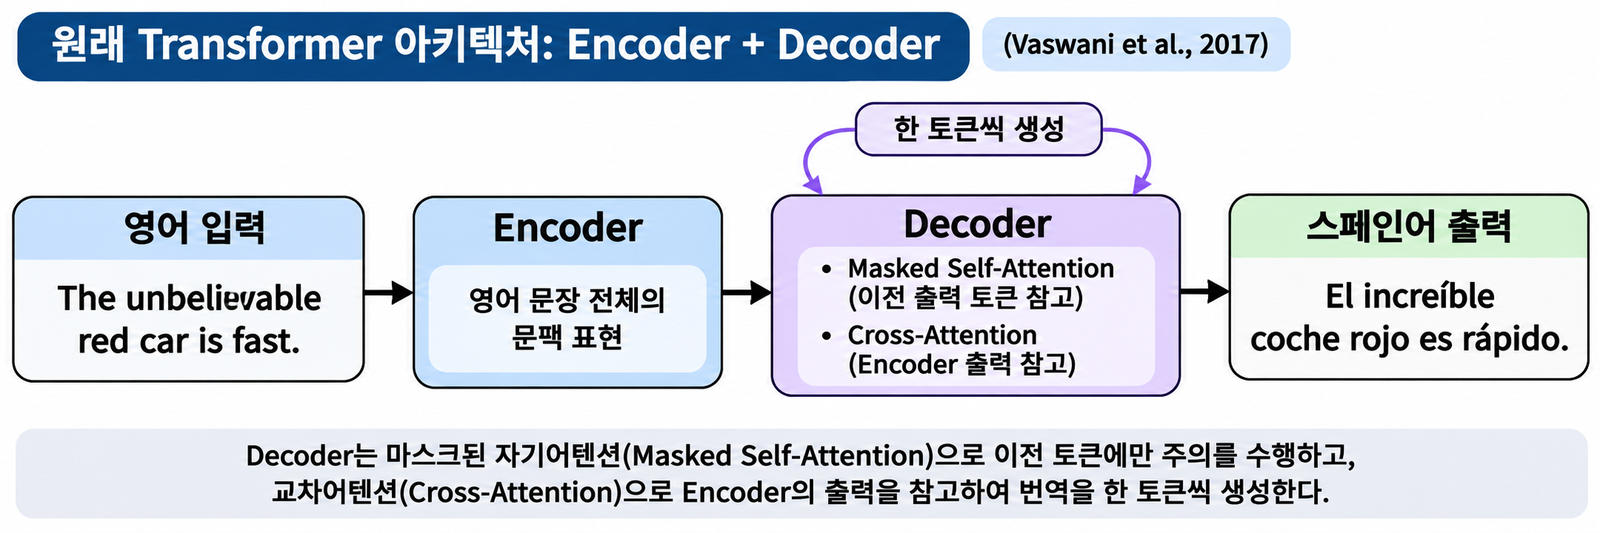

*그림: 원본 Transformer의 구조(Vaswani et al., 2017)를 영어→스페인어 번역 과정에 연결한 개념도. 실제 모델 내부의 반복 층과 세부 연산은 생략했다.*

1. **Encoder:** 영어 문장 전체에서 토큰 사이의 관계를 계산해 입력 문맥을 표현한다.
2. **Decoder:** 시작 토큰에서 출발해 **이전 출력 토큰**(Masked Self-Attention)과 **영어 입력 정보**(Cross-Attention)를 함께 참고한다.
3. **출력:** 다음 스페인어 토큰을 선택하고, 이를 다시 Decoder 입력에 포함하는 과정을 **종료 토큰이 나올 때까지 반복**한다.

이때 `red car`가 `coche rojo`로 번역되듯 **영어와 스페인어의 토큰이 위치별로 일대일 대응할 필요는 없다.** 그림과 예시는 이해를 위한 단순화이며, 실제 모델은 단어보다 작은 **부분단어**(Subword) 토큰을 사용할 수 있고 번역 표현도 여러 가지가 가능하다.

**실습 연결:** 앞 절에서 본 Teacher Forcing과 Causal Mask는 **훈련 과정**을 설명한다. 이번 실습에서는 모델을 다시 훈련하지 않고, **이미 훈련된 Encoder–Decoder 번역 모델에 새로운 영어 문장을 입력**하여 생성 결과를 관찰한다.


## 원본 Transformer에서 LLM으로: 무엇이 달라졌을까?

앞에서는 **Encoder가 입력 문장을 처리하고, Decoder가 번역문을 생성하는 원본 Transformer**를 살펴보았다. 그런데 ChatGPT와 같은 생성형 언어 모델은 왜 별도의 Encoder 없이도 질문에 답하고 글을 쓸 수 있을까?

핵심은 **신경망의 구조**(아키텍처)와 **그 구조를 실제 데이터로 학습한 모델**을 구분하는 것이다.

- **Transformer:** Attention을 이용해 토큰 정보를 처리하는 *신경망 설계 방식*이다. 2017년에 제안된 원래 형태는 Encoder와 Decoder를 함께 사용했다.
- **Decoder-only Transformer:** 원래 구조에서 별도의 Encoder 및 Encoder와 연결하는 Cross-Attention 없이, 주로 **Causal Self-Attention**으로 앞선 토큰을 참고하며 다음 토큰을 예측하도록 만든 구조다. GPT 계열이 대표적이다.
- **LLM(Large Language Model):** 대규모 텍스트·코드 등의 데이터로 학습한 언어 모델을 말한다. 현대의 많은 생성형 LLM은 Decoder-only Transformer 기반이지만, **모든 LLM이 Decoder-only인 것은 아니다.**

### 모델이 문장을 생성할 수 있게 되는 과정

```text
Decoder-only Transformer 구조
       ↓
대규모 텍스트로 사전훈련(Pretraining)
: 앞선 토큰들을 보고 다음 토큰을 맞히도록 학습
       ↓
사전훈련된 언어 모델
       ↓
(선택적으로) 질문·답변 등의 예제로 추가 학습
       ↓
프롬프트를 받아 이어쓰기·질의응답 수행
```

예를 들어 `The capital of Spain is`라는 문장이 주어지면, 모델은 다음 토큰 후보들에 확률을 부여한다. 하나를 선택해 입력 뒤에 붙이고 **다음 토큰 예측을 반복**하면 문장이 생성된다. 이러한 원리는 번역 Decoder에서도 사용했지만, Decoder-only 모델에서는 **영어 입력을 처리하는 별도의 Encoder가 필요하지 않다.**

**기억할 점:** 다음 토큰 예측은 사전훈련의 주요 학습 목표이자 텍스트 생성의 핵심 원리다. 그러나 다음 토큰을 잘 예측하는 것과 **사실에 맞고 사용자의 지시를 잘 따르는 것**은 동일하지 않다. 지시문을 따르는 모델에는 추가 학습이 활용될 수 있으며, 이번 P4에서는 **학습 과정 자체를 구현하지 않고 사전훈련된 모델을 사용**한다.


## Transformer의 세 구조는 오늘날 어디에 사용할까?

원본 Transformer의 **Encoder와 Decoder를 함께 쓰는 방식** 외에도, 목적에 따라 한쪽만 사용하는 모델이 발전했다.

| 구조 | 대표 모델 | 현재의 주요 활용 | 학생들이 기억할 점 |
|---|---|---|---|
| **Encoder-only** | BERT, Sentence-BERT 계열 | 감성분석, 문서 분류, **의미 기반 검색** | 입력 텍스트를 분석하고 의미를 벡터로 표현한다. |
| **Encoder–Decoder** | MarianMT, T5, BART, Whisper | **번역**, 문서 요약, 음성 인식 | 입력을 처리한 뒤 다른 시퀀스를 생성한다. |
| **Decoder-only** | GPT, Llama 계열 | **텍스트 생성**, 질의응답, 코드 작성 | 프롬프트 뒤의 다음 토큰을 반복해서 예측한다. |

**간단한 사례:** 검색창에 `강아지를 키우는 방법`을 입력하면, Encoder 계열 임베딩 모델은 문장의 *의미*를 수치 벡터로 나타내어 `반려견 돌봄 안내`처럼 표현이 다른 관련 문서도 찾는 데 활용할 수 있다. 반면 번역 모델은 `The dog is sleeping.`을 스페인어 문장으로 변환하고, Decoder-only 모델은 `Once upon a time...` 뒤의 이야기를 계속 생성한다.

> **주의:** 이는 구조별 **대표적 활용**이지 엄격한 용도 구분은 아니다. Decoder-only 모델도 번역·요약을 할 수 있고, 모든 검색용 임베딩 모델이 Encoder-only인 것도 아니다. 이 P4 실습에서는 **번역과 텍스트 생성**을 실습하고, P4 프로젝트에서는 **Encoder 계열의 문서 검색**을 사용한다.


## Encoder-only: 문장 임베딩과 의미 검색

Encoder-only Transformer는 입력 문장을 **양방향 Self-Attention**으로 처리하여 문맥을 반영한 표현을 계산한다. BERT와 같은 인코더를 기반으로 만든 **문장 임베딩 모델**은 문장 전체를 하나의 벡터로 표현할 수 있다. (*BERT 자체의 모든 출력이 자동으로 문장 임베딩이 되는 것은 아니며, 문장 유사도에 적합하게 학습·구성된 모델을 사용한다.*)

예를 들어 `야생동물을 같은 개체로 중복 계산하지 않으려면?`이라는 질문을 받았다고 하자.

- 문서 A: `카메라에 같은 동물이 반복 등장하면 관측 횟수와 개체 수를 구분해야 한다.`
- 문서 B: `카메라 배터리는 매주 점검한다.`

문서 A에 질문과 **완전히 같은 단어가 없어도**, 의미가 비슷하면 검색 결과의 상위에 나타날 수 있다.

```text
질문 ------------------→ 문장 임베딩 모델 → 질문 벡터
문서 A, B, ... --------→ 문장 임베딩 모델 → 문서 벡터들
                                           ↓
                                  벡터의 유사도 비교
                                           ↓
                                  관련 문서 상위 3개
```

- **토큰 임베딩:** 한 토큰을 숫자 벡터로 나타낸다.
- **문장 임베딩:** 문장 또는 짧은 문서를 대표하는 하나의 숫자 벡터로 나타낸다.
- **의미 검색:** 질문 벡터와 문서 벡터의 유사도를 비교해 관련 문서를 찾는다. 흔히 **코사인 유사도**를 사용하지만, 이번에는 복잡한 수학적 계산 대신 *의미가 가까운 벡터를 찾는다*는 원리만 이해한다.

**주의:** 유사도가 높다는 것은 내용이 관련 있을 가능성이 높다는 뜻이지, **문서가 사실이라는 뜻은 아니다.**

## 두 구조의 협력: RAG(검색 증강 생성)

의미 검색만으로는 문서를 찾아 보여줄 수 있지만, 질문에 대한 **완성된 문장 형태의 답변**을 작성하지는 않는다. 반대로 Decoder-only 언어 모델에 질문만 넣으면 관련 문서를 확인하지 않고 답변을 생성할 수 있다.

**RAG**(Retrieval-Augmented Generation, 검색 증강 생성)는 이 두 과정을 연결한다.

```text
사용자 질문: "중복 관측 문제는 어떻게 해결하나요?"
                  ↓
① Encoder-only 기반 임베딩 모델
   → 질문과 관련된 문서 25개 중 상위 3개 검색
                  ↓
② 검색된 문서 3개 + 사용자 질문
   → Decoder-only 언어 모델에 함께 입력
                  ↓
③ 문서 내용에 근거한 답변 생성
   → 실제 근거와 일치하는지는 사람이 확인
```

| 단계 | 핵심 기능 | P4에서 사용하는 곳 |
|---|---|---|
| Encoder–Decoder | 입력 시퀀스를 다른 시퀀스로 변환 | **실습:** 영어→스페인어 번역 |
| Encoder-only | 질문·문서를 벡터로 바꾸어 관련 문서 검색 | **프로젝트:** 의미 검색 |
| Decoder-only | 검색된 문서를 참고하여 다음 토큰을 반복 생성 | **프로젝트:** 답변 생성 |

**P4 프로젝트 연결:** 사전에 준비한 **가상 '한솔 생태관측소' 안내 문서 25개**를 사용한다. 학생들은 *단어 일치 검색과 의미 검색*을 비교하고, 검색된 문서를 근거로 생성한 답변에 **문서에 없는 주장이 들어 있는지** 점검한다.

이 과정은 **모델을 새로 학습하지 않고**, 이미 학습된 모델 두 개를 연결해서 사용한다. RAG는 잘못된 답변을 줄이는 데 도움이 될 수 있지만 **항상 정확한 답을 보장하지는 않는다.**

---
# Decoder-only: Encoder 없이도 문장을 생성할까?

GPT 계열처럼 **Decoder만 여러 층 쌓은 모델**을 Decoder-only라고 한다. 영어 원문과 출력 언어를 각각 다른 구성 요소로 분리하지 않고, **모든 입력을 하나의 토큰 시퀀스**(프롬프트)로 처리한다.

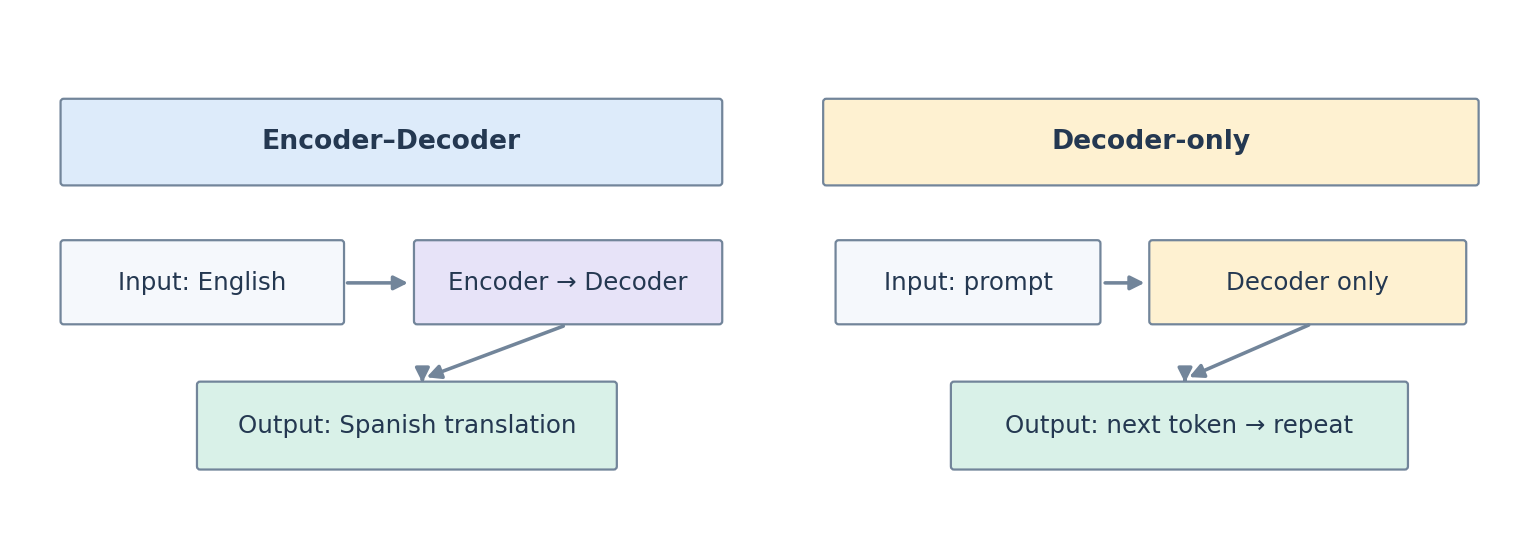

> 주의: Decoder-only의 블록은 원래 Encoder–Decoder의 Decoder를 그대로 복사한 것이 아니다. **Encoder와 연결되는 Cross-Attention은 없고**, 주로 Causal Self-Attention을 사용한다.


## 다음 토큰의 확률분포

예를 들어 모델에 다음과 같이 입력한다.

**`The capital of France is`**

모델은 가능한 다음 **토큰** 각각에 확률을 부여한다.

| 후보 토큰 | 예시 확률 |
|---|---:|
| ` Paris` | 0.65 |
| ` Lyon` | 0.08 |
| ` a` | 0.07 |
| 그 밖의 토큰 | 0.20 |

위 확률은 **설명을 위한 가상 값**이다. 실제 확률은 사전훈련된 작은 모델에서 확인한다.

선택된 다음 토큰을 입력 뒤에 붙여 같은 과정을 반복하면 문장이 길어진다.

```text
The capital of France is
The capital of France is Paris
The capital of France is Paris.
```

이것을 **자기회귀적 생성**(Autoregressive Generation)이라고 한다. 원본 Transformer의 Decoder가 다음 스페인어 토큰을 예측하는 과정과 공통된 원리다.


## Decoder-only의 간단한 활용 두 가지

**활용 ① 텍스트 이어쓰기**

- 입력: `Continue this story: A small dog opened the door...`
- 출력: 주어진 문맥에 이어지는 새로운 문장
- 관찰: 프롬프트가 달라지면 출력도 달라진다.

**활용 ② 간단한 질의응답**

- 입력: `What is the capital of Spain?`
- 출력: 모델이 생성한 답변 텍스트
- 관찰: '답'도 별도의 정답 조회 버튼이 아니라 **다음 토큰 생성을 반복한 결과**다.

둘 다 같은 Decoder-only 생성 원리를 이용한다. 다만 **작은 교육용 모델은 틀리거나 부자연스러운 답변을 생성할 수 있다.**


## 전체 구조를 한 번에 비교

| 구분 | 원본 Transformer Encoder | 원본 Transformer Decoder | Decoder-only 모델 |
|---|---|---|---|
| 주요 역할 | 입력 문장 처리 | 출력 문장 생성 | 프롬프트를 바탕으로 다음 토큰 생성 |
| Self-Attention | 입력 문장 전체 참고 | 이전 출력 토큰만 참고 | 이전 입력·생성 토큰만 참고 |
| Cross-Attention | 없음 | **Encoder 출력 참고** | **없음** |
| 대표 활용 | 번역 모델의 입력 처리 | 번역 모델의 출력 생성 | 이어쓰기, 질의응답 등 |

**정리:** Decoder-only 모델 역시 번역을 수행할 수 있다. 여기서는 **구조의 차이를 명확히 보여주기 위해** Encoder–Decoder는 영어→스페인어 번역으로, Decoder-only는 이어쓰기·질의응답으로 예를 든다.


---
# 학습 내용 확인

1. `token`과 `token ID`는 어떤 차이가 있을까? 임베딩은 왜 필요한가?
2. Q, K, V의 역할을 책 검색에 비유해 설명해 보자.
3. 원본 Transformer의 Encoder 출력은 Decoder의 어느 단계에서 사용되는가?
4. Decoder의 **Masked Self-Attention**과 **Cross-Attention**은 무엇을 다르게 참고하는가?
5. 추론에는 미래 토큰이 아직 없는데도, **훈련에 Causal Mask가 필요한 이유**는 무엇인가? **Teacher Forcing**과 함께 설명해 보자.
6. Encoder–Decoder와 Decoder-only의 가장 중요한 구조적 차이는 무엇인가?
7. 작은 언어 모델의 답변이 자연스럽지 않더라도 다음 토큰 생성 원리를 관찰할 수 있는가?
8. **Transformer 구조**와 **사전훈련된 LLM**은 무엇이 다른가?
9. 문장 임베딩 모델은 표현이 다른 질문과 문서를 어떻게 연결하는가?
10. RAG에서는 검색과 답변 생성 중 무엇을 Encoder 계열과 Decoder-only가 각각 담당하는가?

**다음:** `P4_lab_transformer_llm_section1_edited.ipynb`에서 토큰·Attention·번역·생성을 관찰한 뒤, `P4_project_document_search_RAG.ipynb`에서 실제 검색과 근거 기반 답변 생성을 실험한다.

### 참고 자료

- [Vaswani et al. (2017), *Attention Is All You Need*](https://arxiv.org/pdf/1706.03762)
- [Helsinki-NLP 영어→스페인어 번역 모델](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)
- [SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)
